# Fase C — Implementación de Modelos Predictivos
**Grupo #5** · Continuación del Proyecto 1 (mismo dataset y mismo caso de negocio).

**Problema supervisado principal:** clasificación binaria de `es_grave` (1 = siniestro con lesionado o fallecido, 0 = solo daños) a partir de la información disponible al momento del reporte.
**Problema complementario (objetivo del P1):** clasificación multiclase de la gravedad en los tres niveles definidos en el Proyecto 1, *leve / grave / mortal* (sección 8).

**Modelos supervisados (4):** Regresión Logística, Árbol de Decisión, Random Forest y K-Nearest Neighbors.
**Modelo no supervisado:** K-Means (con Silhouette y Davies-Bouldin) para segmentar las intersecciones de la ciudad, comparado con clustering jerárquico.

**Reglas anti-fuga aplicadas**
- Se usa la partición 80/20 estratificada creada en la Fase B (columna `particion`), antes de cualquier imputación o escalado.
- El escalado vive **dentro de un `Pipeline`**: en cada fold de validación cruzada y en el ajuste final se calcula solo con datos de entrenamiento.
- La búsqueda de hiperparámetros usa validación cruzada **sobre train**; el conjunto de prueba se usa **una sola vez**, al final.

In [1]:
# Librerías
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, precision_recall_curve,
                             classification_report, silhouette_score, davies_bouldin_score)
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.titleweight": "bold"})
SEMILLA = int(os.getenv("RANDOM_STATE", 42))
RUTA_FIG = Path("figuras"); RUTA_FIG.mkdir(exist_ok=True)
COLORES = {"Regresión Logística": "#2E86C1", "Árbol de Decisión": "#28B463",
           "Random Forest": "#C0392B", "KNN": "#8E44AD"}

## 1. Carga del dataset limpio y separación train/test

In [2]:
# Lectura del parquet generado en la Fase B
df = pd.read_parquet("datos_limpios.parquet")
print(df.shape)
df["particion"].value_counts()

(124889, 54)


particion
train    99911
test     24978
Name: count, dtype: int64

In [3]:
# Grupos de variables según el escalador elegido en la Fase B
ESC_MINMAX = ["anio", "mes_sin", "mes_cos", "dia_semana", "ord_vehiculo_mas_pesado"]
ESC_ZSCORE = ["log_frecuencia_direccion"]
ESC_ROBUST = ["yj_num_vehiculos", "n_motos", "n_livianos", "n_transporte_publico", "n_pesados", "n_bicicletas"]
BINARIAS = (["es_fin_de_semana", "periodo_covid", "vehiculos_sin_dato", "tiene_direccion", "es_clinica", "es_interseccion"]
            + [c for c in df.columns if c.startswith(("clase_", "medio_", "via_")) and c not in ("clase_accidente", "medio_reporte", "via_SIN_DATO")])
FEATURES = ESC_MINMAX + ESC_ZSCORE + ESC_ROBUST + BINARIAS
# Se excluyen versiones redundantes que generan colinealidad perfecta:
#  - num_vehiculos crudo, frecuencia_direccion sin log, mes y dias_desde_inicio (ya representados)
#  - ord_franja_vehiculos: tras acotar num_vehiculos a 3 es una recodificación exacta de yj_num_vehiculos
#  - via_SIN_DATO: es exactamente 1 - tiene_direccion
print(f"{len(FEATURES)} variables predictoras")

train, test = df[df.particion == "train"], df[df.particion == "test"]
X_train, y_train = train[FEATURES], train["es_grave"]
X_test, y_test = test[FEATURES], test["es_grave"]
print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"% graves -> train {y_train.mean():.3f} | test {y_test.mean():.3f}")
assert set(train.codigo).isdisjoint(set(test.codigo)), "Hay filas compartidas entre train y test"

37 variables predictoras
Train: (99911, 37) | Test: (24978, 37)
% graves -> train 0.407 | test 0.407


In [4]:
def preprocesador():
    """ColumnTransformer: Min-Max, Z-score y Robust según la forma de cada variable; binarias sin cambio."""
    return ColumnTransformer([
        ("minmax", MinMaxScaler(), ESC_MINMAX),
        ("zscore", StandardScaler(), ESC_ZSCORE),
        ("robust", RobustScaler(), ESC_ROBUST),
        ("binarias", "passthrough", BINARIAS)])

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMILLA)

## 2. Línea base
Un modelo trivial que siempre predice la clase mayoritaria ("solo daños") obtiene un *accuracy* igual a la proporción de esa clase, pero recall y F1 de cero para los graves. Cualquier modelo útil debe superarlo con claridad.

In [5]:
# Línea base: clase mayoritaria
base_acc = 1 - y_test.mean()
print(f"Accuracy de la línea base (siempre 'solo daños'): {base_acc:.3f} | Recall graves: 0.000 | F1: 0.000")

Accuracy de la línea base (siempre 'solo daños'): 0.593 | Recall graves: 0.000 | F1: 0.000


## 3. Entrenamiento con búsqueda de hiperparámetros (validación cruzada en train)
Métrica de selección: **F1 de la clase grave**, porque equilibra *precision* (no enviar recursos de más) y *recall* (no dejar heridos sin atención). Se usa `class_weight="balanced"` donde aplica para compensar el 41/59 de clases.

In [6]:
# Definición de modelos y rejillas
modelos = {
    "Regresión Logística": (LogisticRegression(max_iter=2000, class_weight="balanced"),
                            {"clf__C": [0.1, 1, 10]}),
    "Árbol de Decisión": (DecisionTreeClassifier(class_weight="balanced", random_state=SEMILLA),
                          {"clf__max_depth": [6, 10, 14], "clf__min_samples_leaf": [20, 100]}),
    "Random Forest": (RandomForestClassifier(n_estimators=150, class_weight="balanced", n_jobs=-1, random_state=SEMILLA),
                      {"clf__max_depth": [14, 22], "clf__min_samples_leaf": [5, 20]}),
    "KNN": (KNeighborsClassifier(n_jobs=-1), {"clf__n_neighbors": [15, 35, 75], "clf__weights": ["distance"]}),
}

resultados, ajustados, tiempos = {}, {}, {}
for nombre, (clf, grid) in modelos.items():
    t0 = time.time()
    pipe = Pipeline([("prep", preprocesador()), ("clf", clf)])
    gs = GridSearchCV(pipe, grid, scoring="f1", cv=cv, n_jobs=1 if nombre in ("Random Forest", "KNN") else -1)
    # KNN es costoso en memoria: los hiperparámetros se eligen con una muestra estratificada de train
    if nombre == "KNN":
        muestra = X_train.sample(25000, random_state=SEMILLA).index
        gs.fit(X_train.loc[muestra], y_train.loc[muestra])
        mejor = gs.best_estimator_.set_params(**gs.best_params_).fit(X_train, y_train)   # reajuste con todo train
    else:
        gs.fit(X_train, y_train); mejor = gs.best_estimator_
    ajustados[nombre] = mejor
    tiempos[nombre] = time.time() - t0
    print(f"{nombre:22s} mejores parámetros: {gs.best_params_} | F1 CV = {gs.best_score_:.3f} | {tiempos[nombre]:.0f} s")

Regresión Logística    mejores parámetros: {'clf__C': 10} | F1 CV = 0.731 | 5 s


Árbol de Decisión      mejores parámetros: {'clf__max_depth': 10, 'clf__min_samples_leaf': 20} | F1 CV = 0.754 | 3 s


Random Forest          mejores parámetros: {'clf__max_depth': 14, 'clf__min_samples_leaf': 5} | F1 CV = 0.757 | 44 s


KNN                    mejores parámetros: {'clf__n_neighbors': 35, 'clf__weights': 'distance'} | F1 CV = 0.693 | 4 s


## 4. Evaluación en el conjunto de prueba (nunca visto)

In [7]:
# Métricas en test y F1 en train para detectar sobreajuste
filas = []
probas = {}
for nombre, modelo in ajustados.items():
    pred = modelo.predict(X_test)
    probas[nombre] = modelo.predict_proba(X_test)[:, 1]
    filas.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-score": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, probas[nombre]),
        "F1 train": f1_score(y_train, modelo.predict(X_train)),
        "Tiempo (s)": tiempos[nombre]})
tabla = pd.DataFrame(filas).set_index("Modelo").round(3)
tabla["Brecha F1 (train-test)"] = (tabla["F1 train"] - tabla["F1-score"]).round(3)
tabla.to_csv("tabla_comparativa_modelos.csv")
tabla.sort_values("F1-score", ascending=False)

,Accuracy,Precision,Recall,F1-score,ROC-AUC,F1 train,Tiempo (s),Brecha F1 (train-test)
Modelo,,,,,,,,
Random Forest,0.785,0.699,0.829,0.758,0.878,0.768,44.406,0.010
Árbol de Decisión,0.778,0.685,0.842,0.755,0.876,0.761,2.568,0.006
Regresión Logística,0.761,0.678,0.789,0.729,0.853,0.731,5.299,0.002
KNN,0.782,0.763,0.672,0.715,0.839,0.873,4.096,0.158


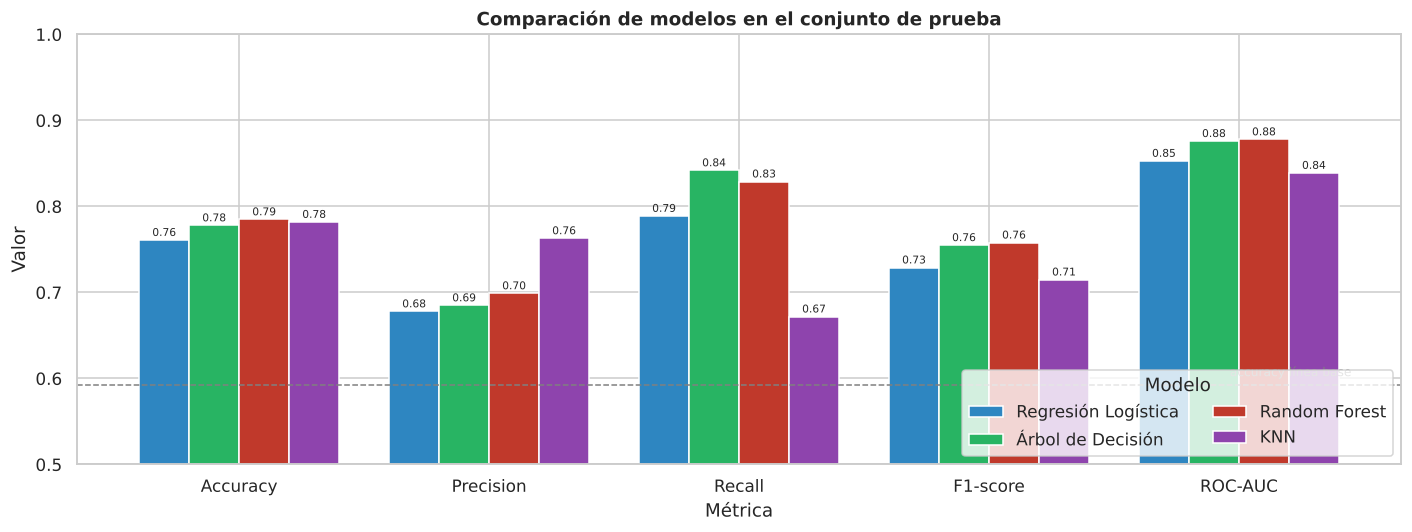

In [8]:
# Gráfico comparativo de métricas
met = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
fig, ax = plt.subplots(figsize=(13, 5))
tabla[met].T.plot(kind="bar", ax=ax, color=[COLORES[m] for m in tabla.index], width=.8, edgecolor="white")
ax.axhline(base_acc, ls="--", color="grey", lw=1); ax.text(4.45, base_acc + .01, "accuracy línea base", ha="right", fontsize=8, color="grey")
ax.set(title="Comparación de modelos en el conjunto de prueba", xlabel="Métrica", ylabel="Valor", ylim=(0.5, 1))
ax.set_xticklabels(met, rotation=0); ax.legend(title="Modelo", loc="lower right", ncol=2)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.2f", fontsize=7, padding=1)
fig.tight_layout(); fig.savefig(RUTA_FIG / "c01_comparacion_metricas.png", bbox_inches="tight"); plt.show()

**Lectura de la tabla:** los cuatro modelos superan con claridad a la línea base (accuracy 0,593 y F1 = 0). **Random Forest** obtiene el mejor F1 (0,758), el mejor accuracy (0,785) y el mejor ROC-AUC (0,878), con una brecha train-test de solo 0,01 (no hay sobreajuste). El **Árbol de Decisión** queda prácticamente empatado (F1 0,755) y tiene el mayor recall (0,842). La **Regresión Logística** es algo inferior (F1 0,729) porque la relación entre variables no es puramente lineal (p. ej., el efecto de la moto depende de si hay carros). **KNN** tiene la mejor precision (0,763) pero el peor recall (0,672) y una brecha train-test de 0,16: memoriza el entrenamiento y deja escapar uno de cada tres siniestros graves.

In [9]:
# ¿Es significativa la diferencia entre el mejor modelo y los demás? Bootstrap de 1 000 remuestreos del test
rng = np.random.default_rng(SEMILLA)
yv = y_test.values
preds = {n: m.predict(X_test) for n, m in ajustados.items()}
filas_bs = []
for rival in ["Árbol de Decisión", "Regresión Logística", "KNN"]:
    dif = []
    for _ in range(1000):
        i = rng.integers(0, len(yv), len(yv))
        dif.append(f1_score(yv[i], preds["Random Forest"][i]) - f1_score(yv[i], preds[rival][i]))
    filas_bs.append({"Comparación": f"Random Forest vs {rival}", "Dif. F1 media": np.mean(dif),
                     "IC 95% inf": np.percentile(dif, 2.5), "IC 95% sup": np.percentile(dif, 97.5)})
pd.DataFrame(filas_bs).set_index("Comparación").round(4)

,Dif. F1 media,IC 95% inf,IC 95% sup
Comparación,,,
Random Forest vs Árbol de Decisión,0.0030,-0.0005,0.0069
Random Forest vs Regresión Logística,0.0290,0.0248,0.0335
Random Forest vs KNN,0.0435,0.0378,0.0496


**Insight:** la ventaja de Random Forest sobre la Regresión Logística y sobre KNN es estadísticamente significativa (el intervalo de confianza no contiene el 0). Frente al Árbol de Decisión la diferencia es de solo 0,003 y su intervalo incluye el 0: ambos modelos son estadísticamente equivalentes en F1, lo cual se tiene en cuenta en la elección del modelo final (sección 10).

### 4.1 Matrices de confusión

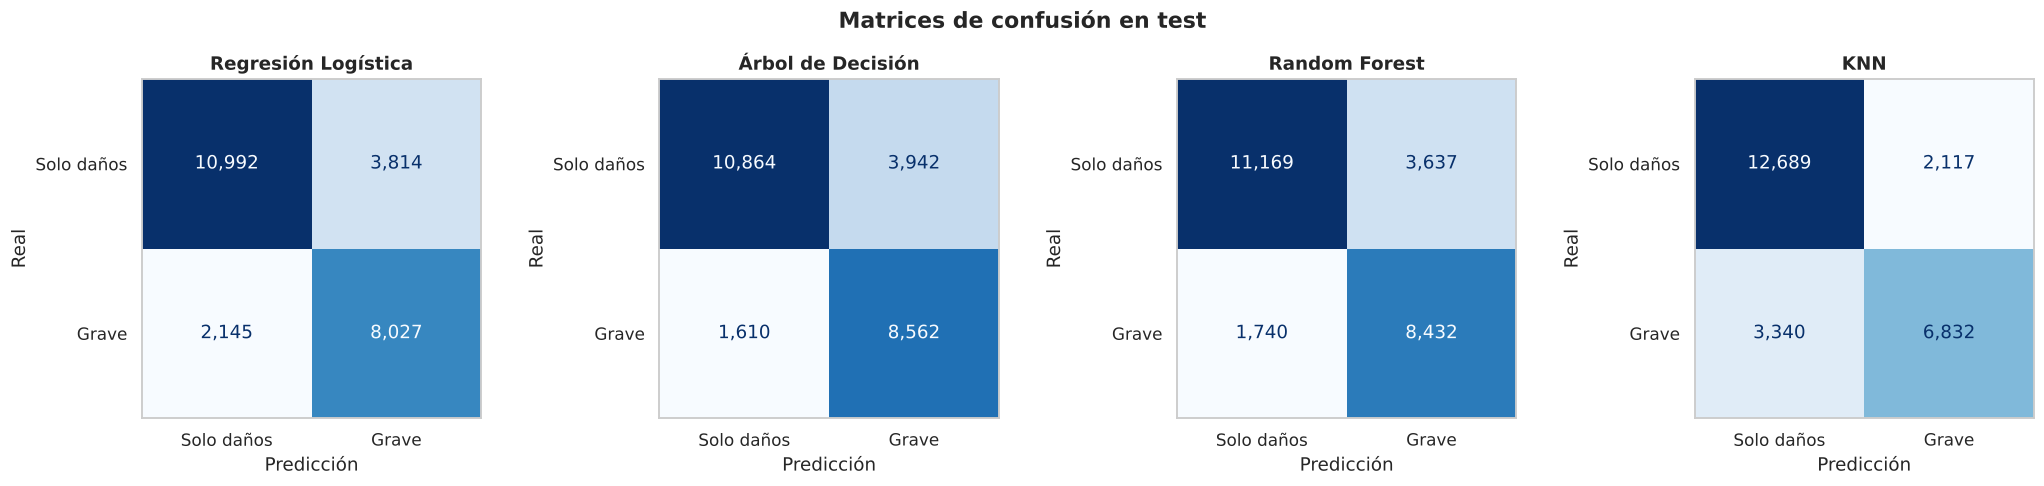

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4.4))
for ax, (nombre, modelo) in zip(axes, ajustados.items()):
    cm = confusion_matrix(y_test, modelo.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=["Solo daños", "Grave"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format=",")
    ax.set(title=nombre, xlabel="Predicción", ylabel="Real"); ax.grid(False)
fig.suptitle("Matrices de confusión en test", fontweight="bold"); fig.tight_layout()
fig.savefig(RUTA_FIG / "c02_matrices_confusion.png", bbox_inches="tight"); plt.show()

**Insight:** de los 10 172 siniestros graves del conjunto de prueba, Random Forest identifica correctamente ≈8 430 (83 %) y el Árbol ≈8 560 (84 %), mientras que KNN solo ≈6 840. El costo de los modelos basados en árboles son ≈3 600–3 900 siniestros de *solo daños* marcados como graves: en un contexto de despacho, es preferible enviar una ambulancia que no se necesitaba a no enviarla cuando sí.

### 4.2 Curvas ROC y Precision-Recall

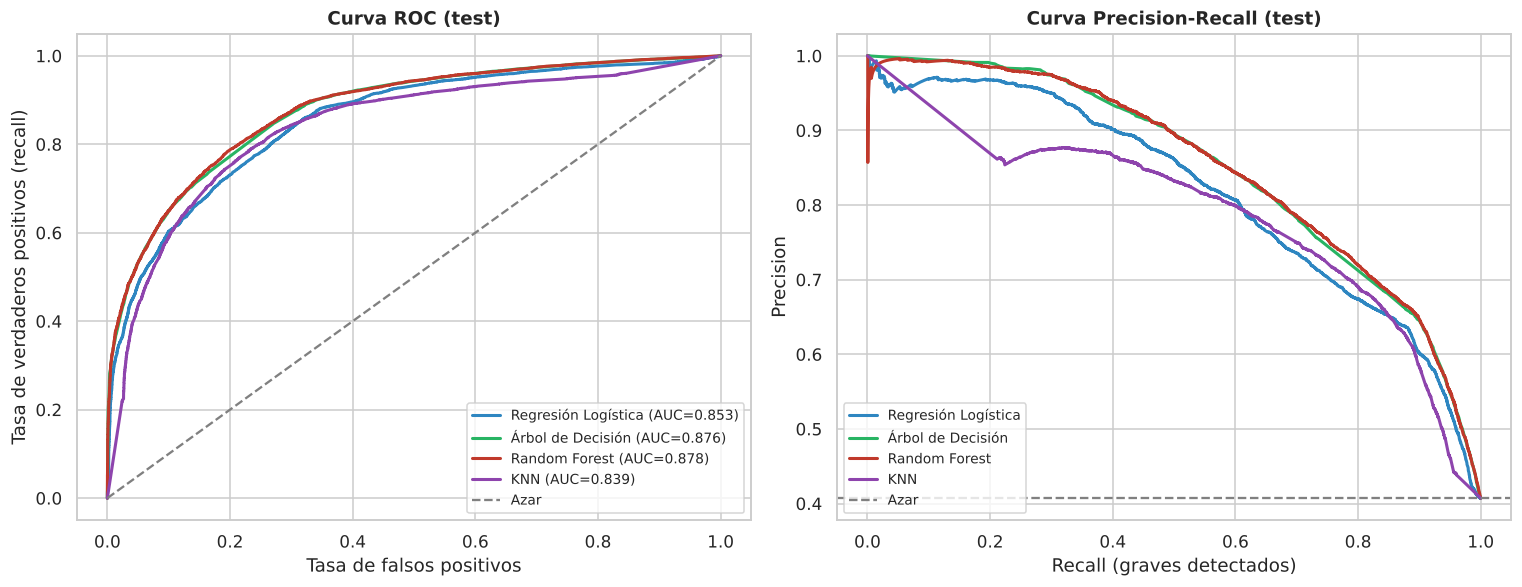

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for nombre, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=COLORES[nombre], lw=2, label=f"{nombre} (AUC={roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rc, pr, color=COLORES[nombre], lw=2, label=nombre)
axes[0].plot([0, 1], [0, 1], ls="--", color="grey", label="Azar")
axes[0].set(title="Curva ROC (test)", xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos (recall)")
axes[1].axhline(y_test.mean(), ls="--", color="grey", label="Azar")
axes[1].set(title="Curva Precision-Recall (test)", xlabel="Recall (graves detectados)", ylabel="Precision")
for ax in axes: ax.legend(loc="lower right" if ax is axes[0] else "lower left", fontsize=9)
fig.tight_layout(); fig.savefig(RUTA_FIG / "c03_roc_pr.png", bbox_inches="tight"); plt.show()

**Insight:** las curvas ROC de Random Forest y del Árbol casi se superponen (AUC ≈ 0,88) y dominan a las de Regresión Logística (0,853) y KNN (0,839) en todo el rango. Un AUC de 0,88 significa que, tomando al azar un siniestro grave y uno de solo daños, el modelo le asigna mayor riesgo al grave el 88 % de las veces.

### 4.3 Reporte de clasificación completo por modelo

In [12]:
for nombre, modelo in ajustados.items():
    print(f"===== {nombre} =====")
    print(classification_report(y_test, modelo.predict(X_test), target_names=["Solo daños", "Grave"], digits=3))

===== Regresión Logística =====
              precision    recall  f1-score   support

  Solo daños      0.837     0.742     0.787     14806
       Grave      0.678     0.789     0.729     10172

    accuracy                          0.761     24978
   macro avg      0.757     0.766     0.758     24978
weighted avg      0.772     0.761     0.763     24978

===== Árbol de Decisión =====
              precision    recall  f1-score   support

  Solo daños      0.871     0.734     0.796     14806
       Grave      0.685     0.842     0.755     10172

    accuracy                          0.778     24978
   macro avg      0.778     0.788     0.776     24978
weighted avg      0.795     0.778     0.780     24978

===== Random Forest =====


              precision    recall  f1-score   support

  Solo daños      0.865     0.754     0.806     14806
       Grave      0.699     0.829     0.758     10172

    accuracy                          0.785     24978
   macro avg      0.782     0.792     0.782     24978
weighted avg      0.797     0.785     0.787     24978

===== KNN =====


              precision    recall  f1-score   support

  Solo daños      0.792     0.857     0.823     14806
       Grave      0.763     0.672     0.715     10172

    accuracy                          0.782     24978
   macro avg      0.778     0.764     0.769     24978
weighted avg      0.780     0.782     0.779     24978



## 5. Interpretabilidad: ¿qué aprendieron los modelos?

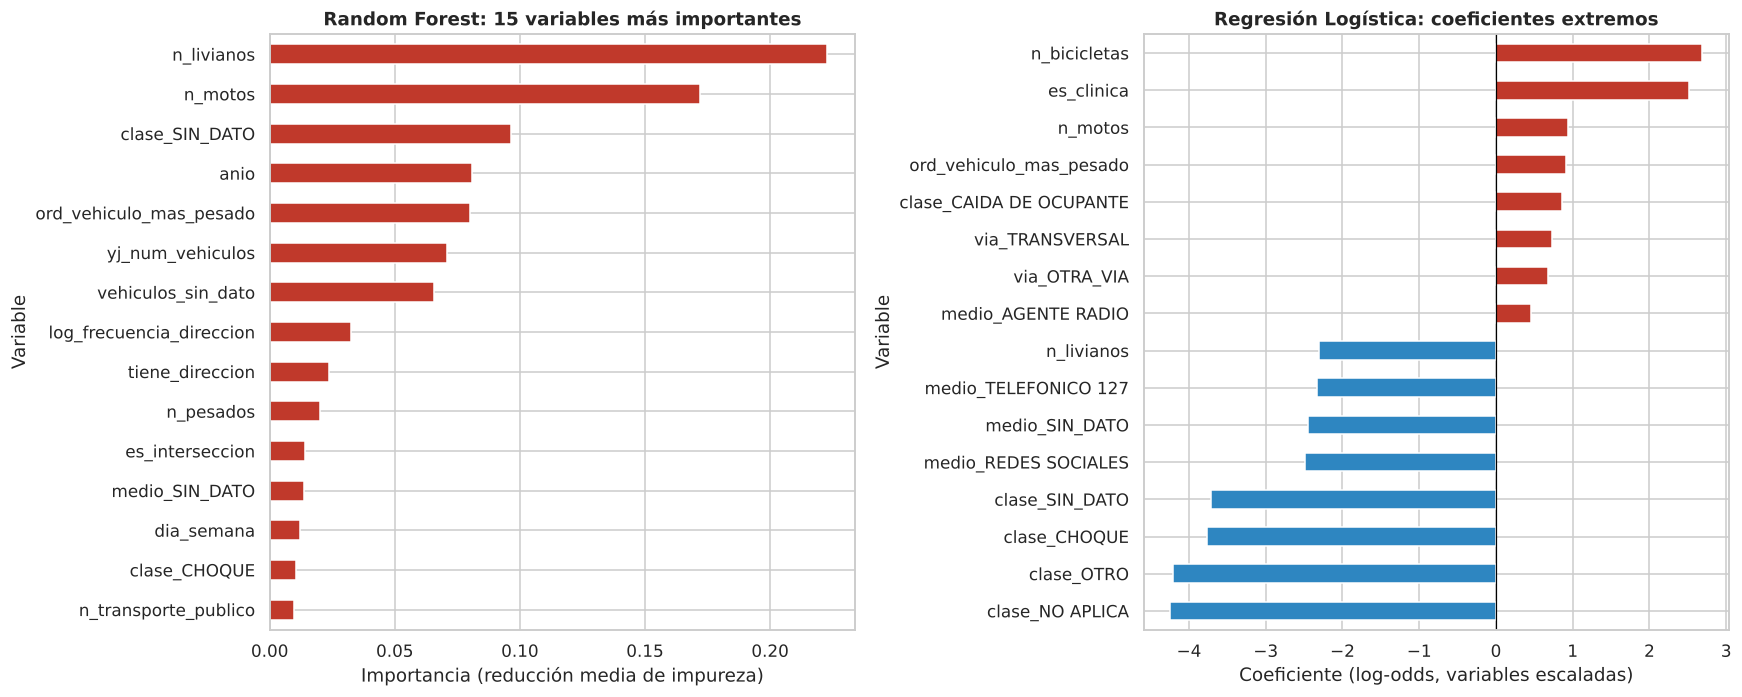

Odds ratio de las variables con mayor efecto (Regresión Logística):


clase_NO APLICA             0.01
clase_OTRO                  0.01
clase_CHOQUE                0.02
clase_SIN_DATO              0.02
medio_REDES SOCIALES        0.08
medio_SIN_DATO              0.09
medio_TELEFONICO 127        0.10
n_livianos                  0.10
medio_AGENTE RADIO          1.58
via_OTRA_VIA                1.96
via_TRANSVERSAL             2.07
clase_CAIDA DE OCUPANTE     2.36
ord_vehiculo_mas_pesado     2.48
n_motos                     2.56
es_clinica                 12.29
n_bicicletas               14.72
dtype: float64

In [13]:
# Importancia de variables (Random Forest) y coeficientes (Regresión Logística)
rf = ajustados["Random Forest"].named_steps["clf"]
imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values(ascending=False)
lr = ajustados["Regresión Logística"].named_steps["clf"]
coef = pd.Series(lr.coef_[0], index=FEATURES).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
imp.head(15)[::-1].plot(kind="barh", ax=axes[0], color="#C0392B")
axes[0].set(title="Random Forest: 15 variables más importantes", xlabel="Importancia (reducción media de impureza)", ylabel="Variable")
top_coef = pd.concat([coef.head(8), coef.tail(8)])
top_coef.plot(kind="barh", ax=axes[1], color=["#2E86C1" if v < 0 else "#C0392B" for v in top_coef])
axes[1].axvline(0, color="black", lw=.8)
axes[1].set(title="Regresión Logística: coeficientes extremos", xlabel="Coeficiente (log-odds, variables escaladas)", ylabel="Variable")
fig.tight_layout(); fig.savefig(RUTA_FIG / "c04_importancia_variables.png", bbox_inches="tight"); plt.show()
print("Odds ratio de las variables con mayor efecto (Regresión Logística):")
np.exp(top_coef).round(2).sort_values()

**Insight:** los dos modelos coinciden en lo esencial y confirman el EDA. En Random Forest, las variables más útiles son el número de **vehículos livianos** (más carros → menos gravedad) y el número de **motos** (más motos → más gravedad), seguidas de la clase de accidente y el vehículo más pesado. En la Regresión Logística, la presencia de una **bicicleta** o que el reporte provenga de una **clínica** multiplica las *odds* de gravedad por más de 10, y una moto por ≈2,6; en cambio, que la clase sea **choque** (frente a atropello, la categoría base) las reduce drásticamente. El `anio` es importante porque captura el cambio de registro de 2022–2024, no un cambio de riesgo.

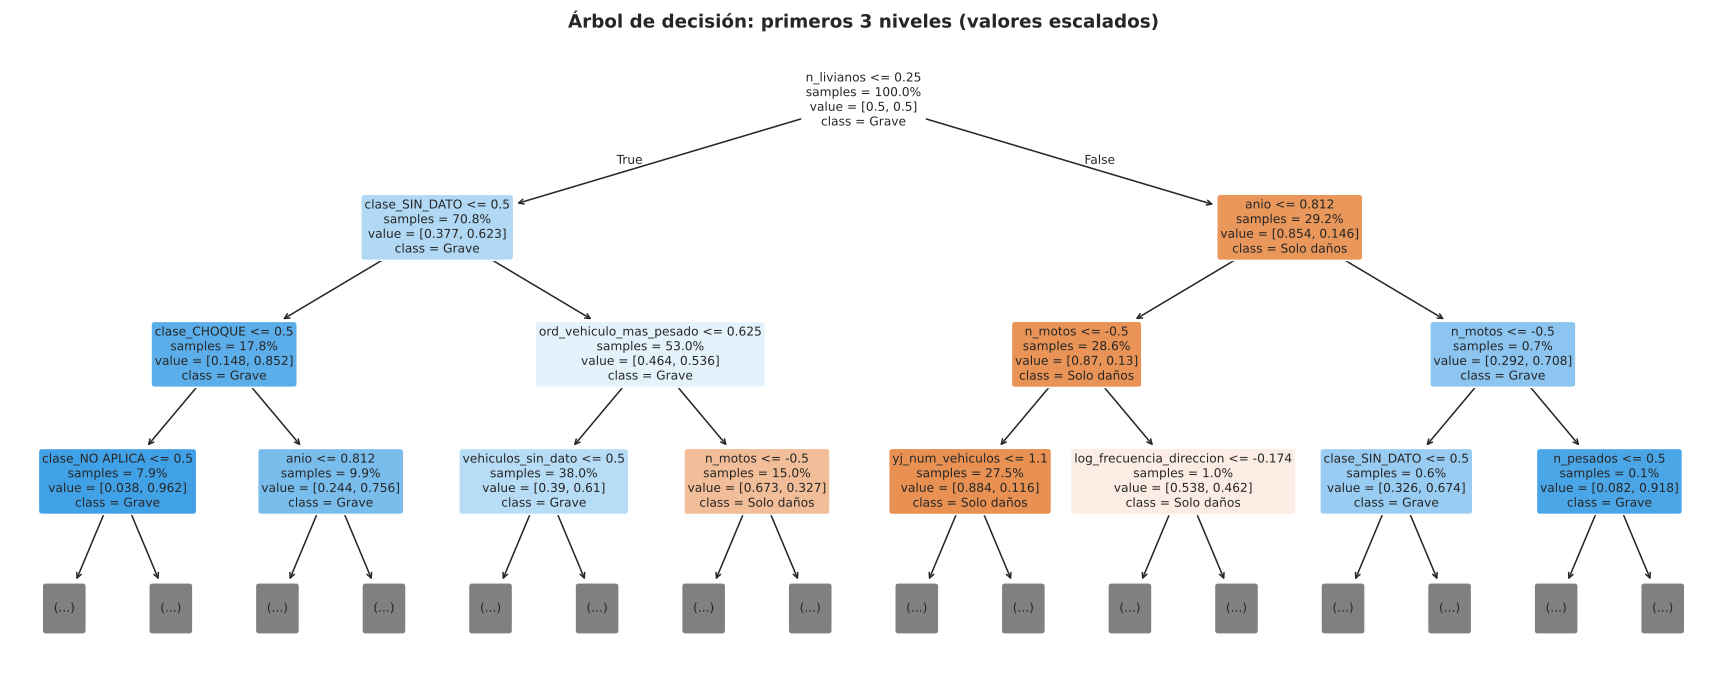

In [14]:
# Árbol de decisión: primeros niveles (reglas legibles para el negocio)
arbol = ajustados["Árbol de Decisión"].named_steps["clf"]
nombres_prep = ajustados["Árbol de Decisión"].named_steps["prep"].get_feature_names_out()
nombres_prep = [n.split("__", 1)[1] for n in nombres_prep]
fig, ax = plt.subplots(figsize=(20, 7.5))
plot_tree(arbol, max_depth=3, feature_names=nombres_prep, class_names=["Solo daños", "Grave"], filled=True,
          rounded=True, fontsize=8, impurity=False, proportion=True, ax=ax)
ax.set_title("Árbol de decisión: primeros 3 niveles (valores escalados)", fontweight="bold")
fig.savefig(RUTA_FIG / "c05_arbol.png", bbox_inches="tight"); plt.show()

**Insight:** (los umbrales están en escala robusta: `n_livianos <= 0.25` equivale a *como máximo 1 vehículo liviano* y `n_motos <= -0.5` a *ninguna moto*). El primer corte del árbol separa los siniestros con **a lo sumo un carro** (mayoría graves) de los que tienen **dos o más** (≈85 % solo daños, en proporción ponderada por clase). Dentro del primer grupo, si la clase de accidente es conocida y no es choque (atropello, caída, volcamiento) ≈96 % es grave; y entre los choques de varios carros, la presencia de una moto vuelve a inclinar la balanza hacia grave. Estas reglas son directamente traducibles a un protocolo de despacho: *"si el reporte menciona moto o bicicleta y no hay carro, o es atropello/caída de ocupante, priorizar ambulancia"*.

## 6. Desempeño por año del modelo final (robustez)
Como la Fase A mostró un cambio en el registro desde 2022, se revisa el F1 del modelo final en test separado por año.

In [15]:
final = "Random Forest"
eval_anio = test.assign(pred=ajustados[final].predict(X_test)).groupby("anio").apply(
    lambda g: pd.Series({"siniestros_test": len(g), "%_graves": g.es_grave.mean(),
                         "accuracy": accuracy_score(g.es_grave, g.pred),
                         "recall": recall_score(g.es_grave, g.pred, zero_division=0),
                         "f1": f1_score(g.es_grave, g.pred, zero_division=0)}), include_groups=False).round(3)
eval_anio

,siniestros_test,%_graves,accuracy,recall,f1
anio,,,,,
2016,3278.0,0.496,0.688,0.884,0.738
2017,3453.0,0.443,0.796,0.868,0.790
2018,4743.0,0.301,0.789,0.747,0.680
2019,4661.0,0.272,0.797,0.625,0.627
2020,2775.0,0.330,0.802,0.753,0.715
2021,2331.0,0.388,0.779,0.846,0.748
2022,1964.0,0.464,0.770,0.848,0.774
2023,984.0,0.879,0.882,0.990,0.937
2024,789.0,0.915,0.915,1.000,0.956


**Insight:** el modelo es estable entre 2016 y 2022 (F1 entre 0,63 y 0,79). Su desempeño es menor en 2018–2019, los años con más siniestros de solo daños registrados (la clase grave es minoritaria, 27–30 %). En 2023–2024 las métricas suben artificialmente porque casi todo lo registrado es grave (88–92 %): ahí el modelo acierta casi siempre, pero por la composición de la base, no por mayor capacidad. Para usarlo en producción convendría reentrenarlo con datos recientes una vez se estabilice el registro.

## 7. Ajuste del umbral de decisión según el uso de negocio
Para despacho de ambulancias es más costoso **no detectar** un siniestro grave que enviar un recurso de más. Se muestra cómo cambia el balance precision/recall del modelo final al mover el umbral (calculado sobre test solo con fines ilustrativos; en producción se fijaría con validación cruzada en train).

In [16]:
p_final = probas[final]
umbrales = pd.DataFrame([{"umbral": u, "precision": precision_score(y_test, p_final >= u),
                          "recall": recall_score(y_test, p_final >= u), "f1": f1_score(y_test, p_final >= u),
                          "%_alertas": (p_final >= u).mean()} for u in [0.3, 0.4, 0.5, 0.6, 0.7]]).round(3)
umbrales

,umbral,precision,recall,f1,%_alertas
0,0.3,0.637,0.906,0.748,0.579
1,0.4,0.657,0.891,0.756,0.553
2,0.5,0.699,0.829,0.758,0.483
3,0.6,0.803,0.675,0.734,0.342
4,0.7,0.858,0.569,0.684,0.270


**Insight:** bajar el umbral a **0,4** sube el recall de 0,83 a 0,89 (se detectan ≈600 siniestros graves más en test) a cambio de que la precision baje de 0,70 a 0,66, con prácticamente el mismo F1 (0,756 vs 0,758). Para despacho de ambulancias se recomienda 0,4; para una campaña con presupuesto limitado (pocas alertas, muy confiables) conviene 0,6–0,7.

## 8. Objetivo del Proyecto 1: clasificación multiclase leve / grave / mortal
El Proyecto 1 definió como objetivo analítico **clasificar la gravedad en tres niveles**. Se entrenan dos modelos multiclase con las mismas variables, la misma partición y el mismo preprocesamiento: Regresión Logística (multinomial) y Random Forest (los hiperparámetros elegidos en la sección 3). La clase *mortal* es solo el 2,7 % de los siniestros, así que se usa `class_weight="balanced"` y se reportan métricas por clase y promedio *macro* (que pesa igual a las tres clases), no solo accuracy.

In [17]:
# Variable objetivo de 3 clases con orden natural (codificada en la Fase B): 0 = leve, 1 = grave, 2 = mortal
CLASES = ["leve", "grave", "mortal"]
y3_train, y3_test = train["ord_gravedad_p1"], test["ord_gravedad_p1"]
print(pd.DataFrame({"train": y3_train.value_counts(normalize=True).sort_index(),
                    "test": y3_test.value_counts(normalize=True).sort_index()}).rename(index=dict(enumerate(CLASES))).round(4))

mejores_rf = {k.replace("clf__", ""): v for k, v in ajustados["Random Forest"].named_steps["clf"].get_params().items()
              if k in ("max_depth", "min_samples_leaf", "n_estimators")}
multi = {
    "Regresión Logística (multinomial)": LogisticRegression(max_iter=3000, class_weight="balanced", C=10),
    "Random Forest (multiclase)": RandomForestClassifier(**mejores_rf, class_weight="balanced", n_jobs=-1, random_state=SEMILLA)}
filas_m, modelos_m = [], {}
for nombre, clf in multi.items():
    m = Pipeline([("prep", preprocesador()), ("clf", clf)]).fit(X_train, y3_train)
    pr = m.predict(X_test); modelos_m[nombre] = m
    rec = recall_score(y3_test, pr, average=None)
    filas_m.append({"Modelo": nombre, "Accuracy": accuracy_score(y3_test, pr),
                    "F1 macro": f1_score(y3_test, pr, average="macro"),
                    "Precision macro": precision_score(y3_test, pr, average="macro"),
                    "Recall macro": recall_score(y3_test, pr, average="macro"),
                    "Recall leve": rec[0], "Recall grave": rec[1], "Recall mortal": rec[2],
                    "ROC-AUC (OvR)": roc_auc_score(y3_test, m.predict_proba(X_test), multi_class="ovr")})
tabla_m = pd.DataFrame(filas_m).set_index("Modelo").round(3)
tabla_m.to_csv("tabla_multiclase.csv")
tabla_m

                  train    test
ord_gravedad_p1                
leve             0.5928  0.5928
grave            0.3800  0.3816
mortal           0.0272  0.0257


,Accuracy,F1 macro,Precision macro,Recall macro,Recall leve,Recall grave,Recall mortal,ROC-AUC (OvR)
Modelo,,,,,,,,
Regresión Logística (multinomial),0.721,0.604,0.579,0.728,0.729,0.707,0.749,0.861
Random Forest (multiclase),0.743,0.649,0.617,0.741,0.719,0.781,0.722,0.887


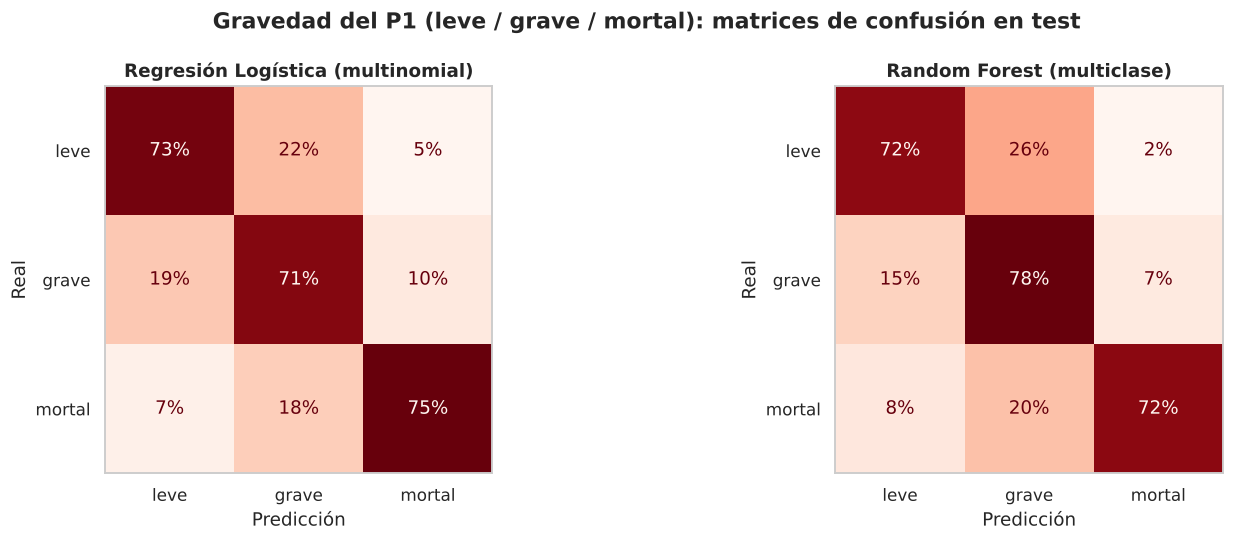

In [18]:
# Matrices de confusión 3x3 (normalizadas por fila: % de cada clase real)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (nombre, m) in zip(axes, modelos_m.items()):
    ConfusionMatrixDisplay.from_predictions(y3_test, m.predict(X_test), display_labels=CLASES, normalize="true",
                                            values_format=".0%", cmap="Reds", colorbar=False, ax=ax)
    ax.set(title=nombre, xlabel="Predicción", ylabel="Real"); ax.grid(False)
fig.suptitle("Gravedad del P1 (leve / grave / mortal): matrices de confusión en test", fontweight="bold")
fig.tight_layout(); fig.savefig(RUTA_FIG / "c09_multiclase_confusion.png", bbox_inches="tight"); plt.show()

In [19]:
# Reporte por clase del mejor modelo multiclase
mejor_m = tabla_m["F1 macro"].idxmax()
print("Mejor modelo multiclase por F1 macro:", mejor_m)
print(classification_report(y3_test, modelos_m[mejor_m].predict(X_test), target_names=CLASES, digits=3))

Mejor modelo multiclase por F1 macro: Random Forest (multiclase)
              precision    recall  f1-score   support

        leve      0.878     0.719     0.791     14806
       grave      0.651     0.781     0.710      9531
      mortal      0.323     0.722     0.446       641

    accuracy                          0.743     24978
   macro avg      0.617     0.741     0.649     24978
weighted avg      0.777     0.743     0.751     24978



**Insight:** con los tres niveles del Proyecto 1, el **Random Forest multiclase** es el mejor (accuracy 0,743; F1 macro 0,649; ROC-AUC 0,887), superando a la Regresión Logística multinomial (F1 macro 0,604). El modelo detecta el **72 % de los siniestros mortales** del conjunto de prueba (≈463 de 641), pero con *precision* de solo 0,32: de cada 3 alertas de "mortal", 2 no lo son (la mayoría son siniestros con lesionados). Es esperable: con los datos del reporte (sin velocidad, edad ni tipo de lesión) un siniestro grave y uno mortal se parecen mucho. Cuando el modelo falla con un mortal, lo confunde sobre todo con *grave* (20 %) y solo en el 8 % con *leve*. **Conclusión de negocio:** la versión binaria (grave vs leve) es la más confiable para despacho; la multiclase sirve como alerta temprana de posibles víctimas fatales (activar protocolo de criminalística o tránsito especializado), aceptando falsas alarmas.

## 9. Modelo no supervisado: segmentación de intersecciones con K-Means
**Continuidad con el P1:** el objetivo del Proyecto 1 era *segmentar barrios por perfil de riesgo*. El CSV real no trae barrio ni comuna, así que se segmenta la unidad geográfica más fina disponible: la **intersección** (`DIM_LUGAR` adaptada).

**Pregunta de negocio:** ¿qué *tipos* de puntos críticos existen en Cali? Se agrupan las intersecciones con al menos 20 siniestros confirmados según su perfil: volumen, gravedad, actores involucrados y momento de ocurrencia. Esto permite diseñar intervenciones distintas para cada tipo de punto (no es lo mismo una intersección de muchos choques leves que una de atropellos y motos).

En clustering no hay variable objetivo ni conjunto de prueba, así que el escalado (Z-score) se ajusta con todas las intersecciones.

In [20]:
# Perfil por intersección
inter = df[df.es_interseccion == 1].groupby("direccion_norm").agg(
    siniestros=("es_grave", "size"), tasa_grave=("es_grave", "mean"),
    pct_moto=("n_motos", lambda s: (s > 0).mean()), pct_pesado=("n_pesados", lambda s: (s > 0).mean()),
    pct_transporte_publico=("n_transporte_publico", lambda s: (s > 0).mean()),
    pct_fin_semana=("es_fin_de_semana", "mean"), vehiculos_promedio=("num_vehiculos", "mean"))
inter = inter[inter.siniestros >= 20].copy()
inter["log_siniestros"] = np.log1p(inter.siniestros)
VARS_TODAS = ["log_siniestros", "tasa_grave", "pct_moto", "pct_pesado", "pct_transporte_publico", "pct_fin_semana", "vehiculos_promedio"]
print(f"Intersecciones con >= 20 siniestros: {len(inter)}")
inter[VARS_TODAS].describe().round(2)

Intersecciones con >= 20 siniestros: 314


,log_siniestros,tasa_grave,pct_moto,pct_pesado,pct_transporte_publico,pct_fin_semana,vehiculos_promedio
count,314.00,314.00,314.00,314.00,314.00,314.00,314.00
mean,3.58,0.47,0.56,0.14,0.10,0.26,1.98
std,0.47,0.14,0.13,0.08,0.08,0.09,0.11
min,3.04,0.04,0.23,0.00,0.00,0.05,1.15
25%,3.18,0.37,0.48,0.09,0.04,0.20,1.93
50%,3.43,0.47,0.55,0.14,0.08,0.26,2.00
75%,3.89,0.56,0.64,0.18,0.13,0.31,2.04
max,5.11,1.00,0.92,0.40,0.54,0.62,2.22


In [21]:
# Selección de variables para el clustering: se compara el set completo con uno reducido.
# pct_pesado, pct_fin_semana y vehiculos_promedio casi no varían entre intersecciones y agregan ruido a la distancia.
def evaluar_set(cols):
    """Silhouette y Davies-Bouldin de K-Means para k = 2..8 con un set de variables."""
    X = StandardScaler().fit_transform(inter[cols]); filas = []
    for k in range(2, 9):
        lab = KMeans(n_clusters=k, n_init=20, random_state=SEMILLA).fit_predict(X)
        filas.append({"k": k, "silhouette": silhouette_score(X, lab), "davies_bouldin": davies_bouldin_score(X, lab)})
    return pd.DataFrame(filas).set_index("k")
VARS_CL = ["log_siniestros", "tasa_grave", "pct_moto", "pct_transporte_publico"]
pd.concat({"7 variables": evaluar_set(VARS_TODAS), "4 variables (elegido)": evaluar_set(VARS_CL)}, axis=1).round(3)

7 variables                4 variables (elegido)               
   silhouette davies_bouldin            silhouette davies_bouldin
k                                                                
2       0.174          1.916                 0.233          1.556
3       0.150          1.752                 0.255          1.296
4       0.160          1.618                 0.279          1.100
5       0.170          1.386                 0.240          1.204
6       0.167          1.453                 0.231          1.218
7       0.156          1.490                 0.223          1.255
8       0.152          1.469                 0.201          1.293

In [22]:
# Matriz final para clustering (Z-score: no hay split en aprendizaje no supervisado)
X_cl = StandardScaler().fit_transform(inter[VARS_CL])

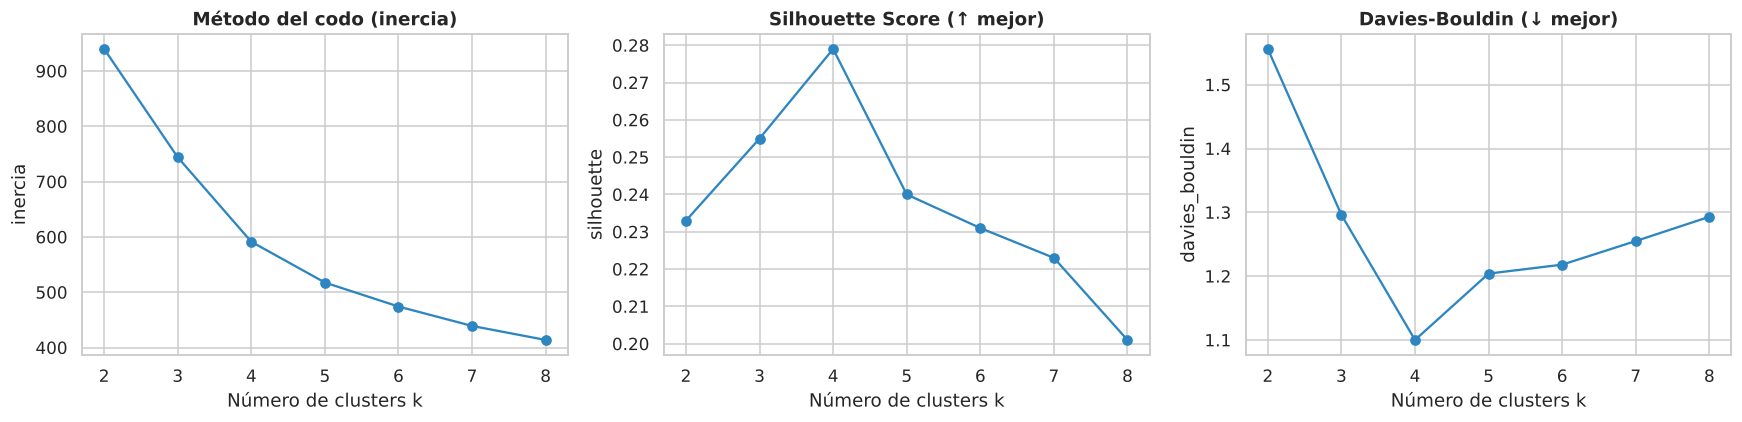

,inercia,silhouette,davies_bouldin
k,,,
2,939.710,0.233,1.556
3,743.934,0.255,1.296
4,591.245,0.279,1.100
5,517.458,0.240,1.204
6,474.116,0.231,1.218
7,439.020,0.223,1.255
8,413.661,0.201,1.293


In [23]:
# Selección de k: inercia (codo), Silhouette (más alto = mejor) y Davies-Bouldin (más bajo = mejor)
eval_k = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEMILLA).fit(X_cl)
    eval_k.append({"k": k, "inercia": km.inertia_, "silhouette": silhouette_score(X_cl, km.labels_),
                   "davies_bouldin": davies_bouldin_score(X_cl, km.labels_)})
eval_k = pd.DataFrame(eval_k).set_index("k").round(3)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, t in zip(axes, eval_k.columns, ["Método del codo (inercia)", "Silhouette Score (↑ mejor)", "Davies-Bouldin (↓ mejor)"]):
    ax.plot(eval_k.index, eval_k[col], marker="o", color="#2E86C1"); ax.set(title=t, xlabel="Número de clusters k", ylabel=col)
fig.tight_layout(); fig.savefig(RUTA_FIG / "c06_seleccion_k.png", bbox_inches="tight"); plt.show()
eval_k

In [24]:
# Ajuste final con el k elegido y comparación con clustering jerárquico (Ward)
K = int(eval_k["silhouette"].idxmax())   # k con mejor Silhouette; se verifica que también minimice Davies-Bouldin
print(f"k elegido = {K} | k con menor Davies-Bouldin = {eval_k['davies_bouldin'].idxmin()}")
km = KMeans(n_clusters=K, n_init=50, random_state=SEMILLA).fit(X_cl)
inter["cluster"] = km.labels_
ward = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(X_cl)
comp_cl = pd.DataFrame({
    "Silhouette": [silhouette_score(X_cl, km.labels_), silhouette_score(X_cl, ward.labels_)],
    "Davies-Bouldin": [davies_bouldin_score(X_cl, km.labels_), davies_bouldin_score(X_cl, ward.labels_)]},
    index=[f"K-Means (k={K})", f"Jerárquico Ward (k={K})"]).round(3)
comp_cl

k elegido = 4 | k con menor Davies-Bouldin = 4


,Silhouette,Davies-Bouldin
K-Means (k=4),0.279,1.100
Jerárquico Ward (k=4),0.223,1.277


In [25]:
# Perfil de cada cluster (valores originales) para nombrarlos en lenguaje de negocio
perfil = inter.groupby("cluster")[VARS_TODAS[1:] + ["siniestros"]].mean().round(3)
perfil.insert(0, "n_intersecciones", inter.cluster.value_counts().sort_index())
perfil

,n_intersecciones,tasa_grave,pct_moto,pct_pesado,pct_transporte_publico,pct_fin_semana,vehiculos_promedio,siniestros
cluster,,,,,,,,
0,33,0.531,0.522,0.120,0.269,0.248,1.926,32.303
1,105,0.347,0.465,0.169,0.076,0.252,2.018,28.305
2,94,0.582,0.681,0.101,0.065,0.279,1.941,27.521
3,82,0.464,0.551,0.147,0.091,0.265,1.989,70.902


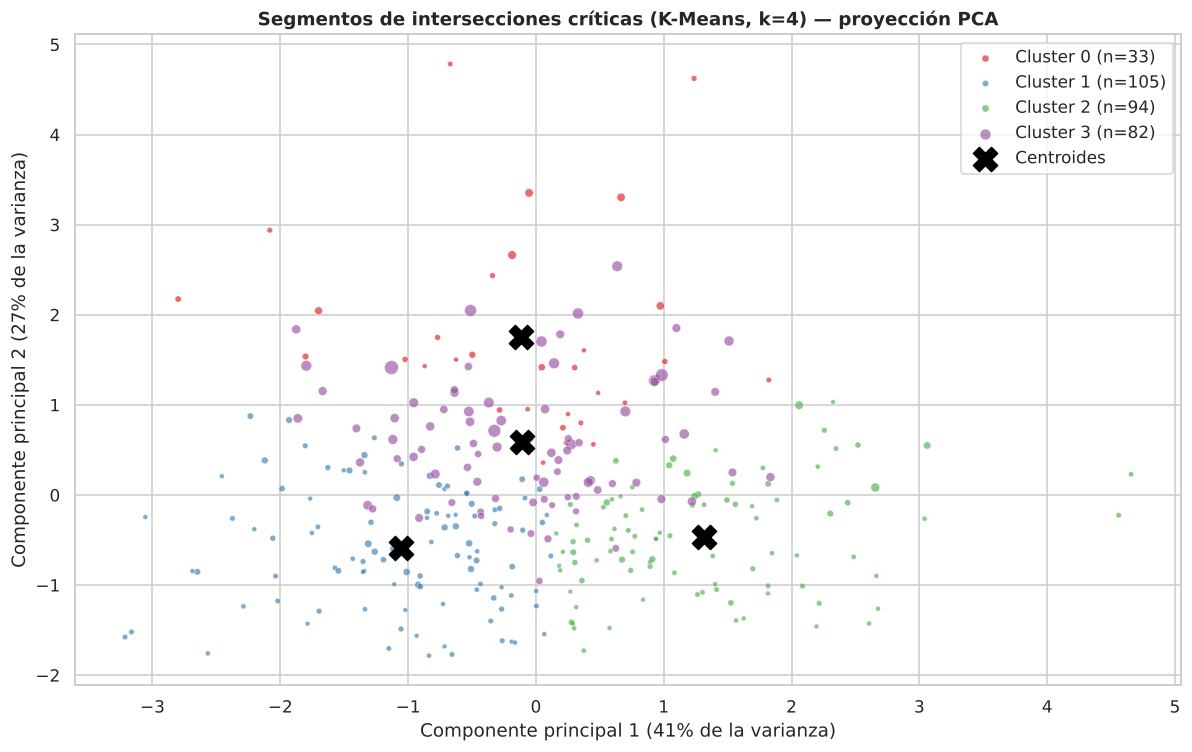

In [26]:
# Visualización de clusters en 2D con PCA
pca = PCA(n_components=2, random_state=SEMILLA).fit(X_cl)
coords = pca.transform(X_cl)
fig, ax = plt.subplots(figsize=(11, 7))
paleta = sns.color_palette("Set1", K)
for c in range(K):
    m = inter.cluster.values == c
    ax.scatter(coords[m, 0], coords[m, 1], s=np.clip(inter.siniestros.values[m] / 2, 8, 200), alpha=.65,
               color=paleta[c], label=f"Cluster {c} (n={m.sum()})", edgecolor="white", lw=.4)
cent = pca.transform(km.cluster_centers_)
ax.scatter(cent[:, 0], cent[:, 1], marker="X", s=250, color="black", label="Centroides")
ax.set(title=f"Segmentos de intersecciones críticas (K-Means, k={K}) — proyección PCA",
       xlabel=f"Componente principal 1 ({pca.explained_variance_ratio_[0]:.0%} de la varianza)",
       ylabel=f"Componente principal 2 ({pca.explained_variance_ratio_[1]:.0%} de la varianza)")
ax.legend(); fig.tight_layout(); fig.savefig(RUTA_FIG / "c07_clusters_pca.png", bbox_inches="tight"); plt.show()

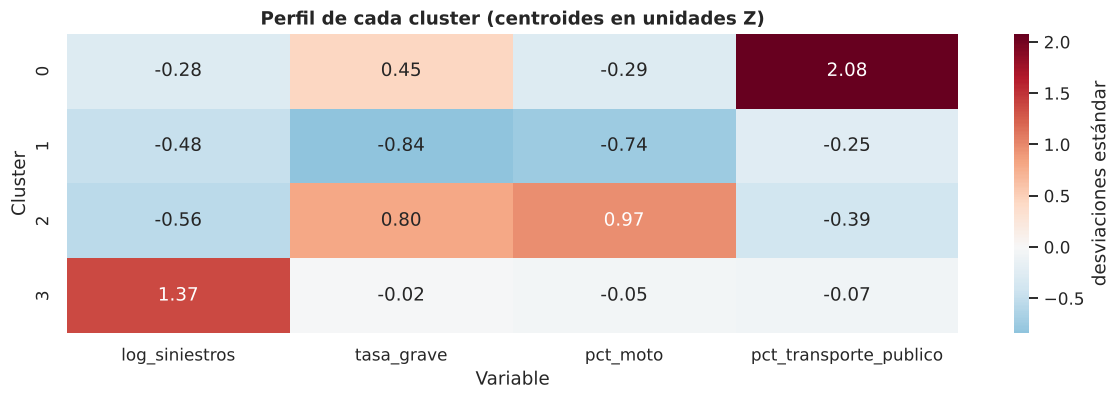

In [27]:
# Heatmap del perfil estandarizado de cada cluster
perfil_z = pd.DataFrame(km.cluster_centers_, columns=VARS_CL)
fig, ax = plt.subplots(figsize=(11, 3.8))
sns.heatmap(perfil_z, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax, cbar_kws={"label": "desviaciones estándar"})
ax.set(title="Perfil de cada cluster (centroides en unidades Z)", xlabel="Variable", ylabel="Cluster")
fig.tight_layout(); fig.savefig(RUTA_FIG / "c08_perfil_clusters.png", bbox_inches="tight"); plt.show()

In [28]:
# Intersecciones representativas por cluster (las de más siniestros)
for c in range(K):
    print(f"Cluster {c}:", ", ".join(inter[inter.cluster == c].sort_values("siniestros", ascending=False).head(4).index.str.title()))
inter.reset_index()[["direccion_norm", "siniestros", "tasa_grave", "cluster"]].to_csv("segmentos_intersecciones.csv", index=False)

Cluster 0: Calle 5 Con Carrera 50, Calle 73 Con Diagonal 15, Calle 15 Con Carrera 15, Calle 34 Con Carrera 1
Cluster 1: Calle 16 Con Carrera 80, Calle 16 Con Carrera 83, Avenida 3N Con Calle 70, Calle 6 Con Carrera 42
Cluster 2: Carrera 8 Con Calle 70, Calle 5 Con Carrera 36, Calle 5 Con Carrera 38, Calle 5 Con Carrera 24
Cluster 3: Calle 25 Con Carrera 98, Calle 10 Con Carrera 39, Calle 70 Con Carrera 8, Calle 16 Con Carrera 100


**Lectura de los segmentos (k = 4, Silhouette 0,279, Davies-Bouldin 1,10):**

| Cluster | Nombre de negocio | Perfil | Intervención sugerida |
|---|---|---|---|
| 0 (33) | **Corredores de transporte público** | 27 % de siniestros con bus/buseta (2,7 veces el promedio), 53 % graves | Carriles exclusivos, control de paraderos, capacitación de conductores del SITM |
| 1 (105) | **Puntos de choques leves** | Menor gravedad (35 %) y menos motos | Semaforización, señalización, agilizar el arreglo directo |
| 2 (94) | **Puntos de motos y alta gravedad** | 68 % con moto y 58 % graves, el mayor riesgo por siniestro | Control de velocidad, cámaras, campañas a motociclistas, pasos peatonales seguros |
| 3 (82) | **Puntos negros de alto volumen** | ≈71 siniestros cada uno (2,5 veces más que los demás), gravedad media | Prioridad 1 en rediseño vial: es donde se concentran más casos en total |

**Calidad del clustering:** un Silhouette de 0,28 indica segmentos con fronteras moderadas (las intersecciones forman más un continuo que grupos totalmente separados), pero K-Means supera al clustering jerárquico (0,223) y los 4 grupos tienen perfiles claramente distintos e interpretables. Quitar las variables casi constantes entre intersecciones mejoró el Silhouette de 0,16 a 0,28.

## 10. Elección del modelo final

**Modelo elegido: Random Forest** (umbral recomendado 0,4 para despacho).

1. **Precisión predictiva:** mejor F1 (0,758), accuracy (0,785) y ROC-AUC (0,878) en el conjunto de prueba; supera de forma significativa a la Regresión Logística y a KNN.
2. **Generalización:** brecha train-test de 0,01; el promedio de muchos árboles es más estable ante cambios en los datos que un solo árbol (por ejemplo, un árbol cambia sus cortes si se agregan unos pocos meses de datos).
3. **Probabilidades más finas:** al promediar 150 árboles, produce probabilidades continuas que permiten ajustar el umbral según el uso (despacho vs campañas); un solo árbol solo da tantos valores como hojas.
4. **Interpretabilidad suficiente:** la importancia de variables explica qué lo mueve. Como el **Árbol de Decisión** tiene un desempeño estadísticamente casi idéntico, se recomienda usarlo como **modelo explicativo** para comunicar reglas sencillas al personal de despacho.

**Para el objetivo multiclase del P1** (leve / grave / mortal) también se elige **Random Forest** (F1 macro 0,649 frente a 0,604 de la Regresión Logística), como modelo complementario de alerta de posibles víctimas fatales.

Se descartan la Regresión Logística (menor F1 por relaciones no lineales, aunque es la más fácil de explicar en *odds*) y KNN (sobreajuste y bajo recall: deja escapar el 33 % de los graves).